# Laboratorium: Analiza i przetwarzanie obrazów w różnych przestrzeniach barw

**Temat:** RGB, HSV, YCrCb i CIELAB – reprezentacja barw i segmentacja obiektów

## Cel ćwiczenia
Celem jest poznanie różnych sposobów reprezentacji informacji o kolorze oraz sprawdzenie, jak wybór przestrzeni barw wpływa na analizę i segmentację obrazu.


## 1. Przygotowanie środowiska

Wykorzystamy NumPy do operacji na tablicach, Matplotlib do wyświetlania obrazów oraz OpenCV do konwersji przestrzeni barw i operacji na maskach.

W tym notebooku zmienna `obraz` przechowuje dane w kolejności RGB. Pamiętaj: `cv2.imread()` domyślnie wczytuje obraz w kolejności BGR, dlatego po wczytaniu trzeba wykonać konwersję BGR→RGB.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

NumPy: 2.5.3
OpenCV: 5.0.0


## 2. Obraz do analizy

Aby wszystkie komórki można było uruchomić bez pobierania dodatkowych plików, generujemy prostą scenę testową: czerwony i niebieski obiekt na zielonym tle, zróżnicowana jasność i delikatne zaburzenia wartości pikseli.


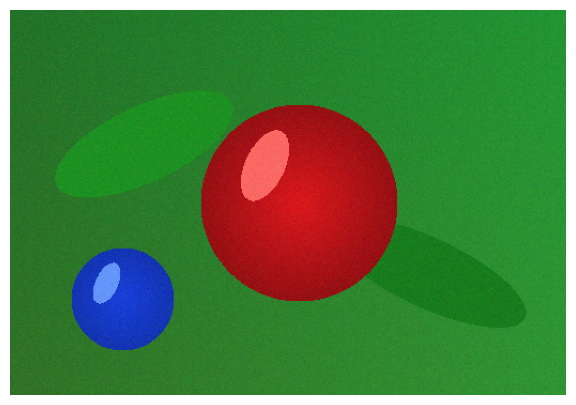

In [2]:
import matplotlib.pyplot as plt
from scena_rgb import generuj_scene

kolory = {
    "tlo":      (35, 115, 40),
    "lisc1":    (30, 145, 35),
    "lisc2":    (25, 125, 30),
    "obiekt1":  (220, 25, 30),
    "obiekt2":  (25, 65, 220),
    "refleks1": (250, 105, 100),
    "refleks2": (100, 150, 250)
}
obraz = generuj_scene(kolory)

plt.figure(figsize=(8, 5))
plt.imshow(obraz)
plt.axis("off")
plt.show()

## 3. Przestrzeń RGB – składowe koloru

W modelu RGB każdy piksel jest opisany przez trzy składowe: R (czerwień), G (zieleń) i B (niebieski). Dla obrazu 8-bitowego każda składowa przyjmuje wartości od 0 do 255.

Obraz kolorowy jest tablicą trójwymiarową o wymiarach:

\[
(H, W, 3)
\]

gdzie \(H\) to wysokość obrazu, \(W\) – szerokość, a ostatni wymiar zawiera kanały RGB.

Wymiary: (360, 520, 3)
Typ danych: uint8
Zakres: 0 – 255


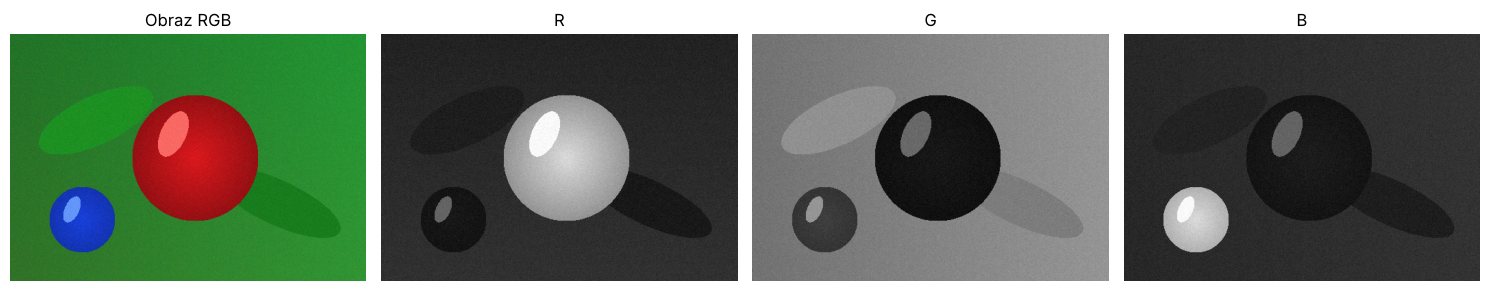

In [3]:
print("Wymiary:", obraz.shape)
print("Typ danych:", obraz.dtype)
print("Zakres:", obraz.min(), "–", obraz.max())

R = obraz[:, :, 0]
G = obraz[:, :, 1]
B = obraz[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(obraz); ax[0].set_title("Obraz RGB")
ax[1].imshow(R, cmap="gray", vmin=0, vmax=255); ax[1].set_title("R")
ax[2].imshow(G, cmap="gray", vmin=0, vmax=255); ax[2].set_title("G")
ax[3].imshow(B, cmap="gray", vmin=0, vmax=255); ax[3].set_title("B")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

### Zadanie 1. Analiza kanałów RGB
1. Wybierz punkty należące do czerwonego obiektu, niebieskiego obiektu i punkt należący do zielonego tła (skorzystaj z poniższej sceny testowej, **współrzędne piksela podaje się jako (wiersz, kolumna)**)
2. Odczytaj wartości RGB w tych trzech punktach.
3. Wyjaśnij, które składowe mają największy udział w kolorze każdego punktu.

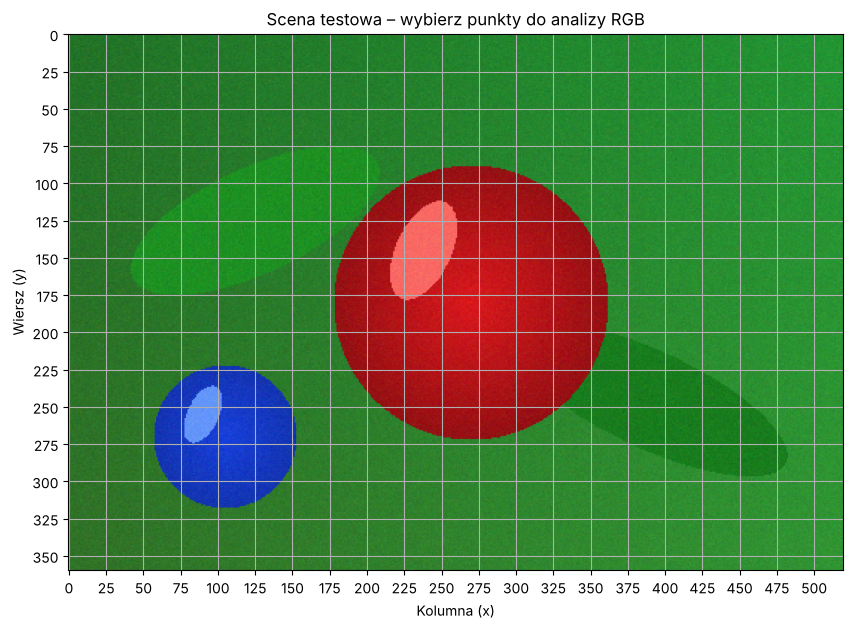

In [4]:
plt.figure(figsize=(10, 7))
plt.imshow(obraz)
plt.title("Scena testowa – wybierz punkty do analizy RGB")
plt.xlabel("Kolumna (x)")
plt.ylabel("Wiersz (y)")
plt.xticks(np.arange(0, 520, 25))
plt.yticks(np.arange(0, 360, 25))
plt.grid()
plt.show()

czerwony obiekt   (wiersz=180, kolumna=270):  R=219  G= 39  B= 31
niebieski obiekt  (wiersz=270, kolumna=105):  R= 23  G= 69  B=214
zielone tło       (wiersz=40, kolumna=450):  R= 42  G=142  B= 44


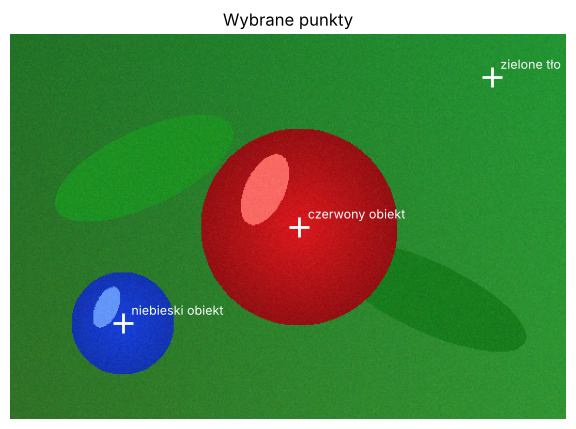

In [5]:
# Zadanie 1 – rozwiązanie: punkty (wiersz, kolumna)
punkty = {
    "czerwony obiekt":  (180, 270),   # środek dużej kulki
    "niebieski obiekt": (270, 105),   # środek małej kulki
    "zielone tło":      (40, 450),    # prawy górny róg, poza liśćmi
}

plt.figure(figsize=(8, 5))
plt.imshow(obraz)
for nazwa, (w, k) in punkty.items():
    R_, G_, B_ = obraz[w, k, :]
    print(f"{nazwa:17s} (wiersz={w}, kolumna={k}):  R={R_:3d}  G={G_:3d}  B={B_:3d}")
    plt.plot(k, w, "w+", markersize=14, markeredgewidth=2)
    plt.text(k + 8, w - 8, nazwa, color="white", fontsize=9)
plt.title("Wybrane punkty")
plt.axis("off")
plt.show()

**Odpowiedź do Zadania 1**

| Punkt | (wiersz, kolumna) | R | G | B | Dominująca składowa |
|---|---|---|---|---|---|
| czerwony obiekt | (180, 270) | 219 | 39 | 31 | **R** |
| niebieski obiekt | (270, 105) | 23 | 69 | 214 | **B** |
| zielone tło | (40, 450) | 42 | 142 | 44 | **G** |

- **Czerwony obiekt** – składowa R jest bardzo duża (≈220), a G i B są małe (≈30–40), więc barwa jest prawie czystą czerwienią.
- **Niebieski obiekt** – dominuje składowa B (≈214). Składowa G (≈69) jest trochę większa niż R, co daje lekko „chłodny”, błękitnawy odcień niebieskiego.
- **Zielone tło** – dominuje składowa G (≈142), R i B są małe i zbliżone. Ponieważ G nie jest bliskie 255, zieleń jest ciemna.

Wartości różnią się o kilka jednostek od kolorów ze słownika `kolory`, bo scena ma gradient jasności i dodany szum gaussowski.

## 4. Przestrzeń HSV – odcień, nasycenie i jasność

HSV opisuje kolor za pomocą:
- **H (Hue)** – odcień, czyli rodzaj barwy;
- **S (Saturation)** – nasycenie barwy;
- **V (Value)** – wartość/jasność.

Oddzielenie informacji o rodzaju barwy od jasności i nasycenia może ułatwiać wybieranie obiektów na podstawie koloru.

Konwersję wykonujemy gotową funkcją OpenCV. Dla obrazu 8-bitowego OpenCV używa zakresu H: 0–179 oraz S i V: 0–255.

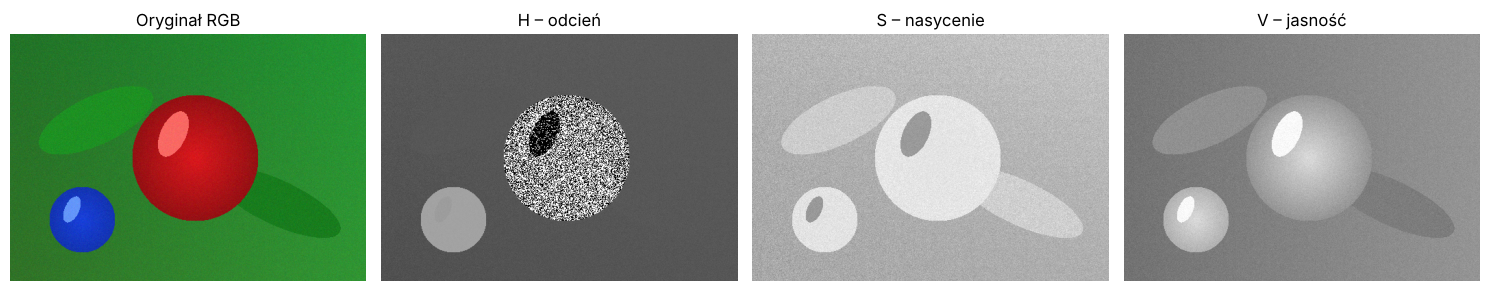

In [6]:
hsv = cv2.cvtColor(obraz, cv2.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(obraz); ax[0].set_title("Oryginał RGB")
ax[1].imshow(H, cmap="gray", vmin=0, vmax=179); ax[1].set_title("H – odcień")
ax[2].imshow(S, cmap="gray", vmin=0, vmax=255); ax[2].set_title("S – nasycenie")
ax[3].imshow(V, cmap="gray", vmin=0, vmax=255); ax[3].set_title("V – jasność")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

### Zadanie 2. Zmiana koloru obiektu z wykorzystaniem przestrzeni HSV
1. Otwórz stronę Color Picker ( https://utilitiesbunker.com/tools/color-picker?utm_source=chatgpt.com ).
2. Wybierz kolor żółty. Odczytaj i zanotuj jego wartości H, S i V.
3. Przygotuj dwa warianty koloru żółtego:
   - kolor podstawowy – intensywny żółty,
   - kolor jaśniejszy – odpowiadający jasnej plamce (refleksowi) na powierzchni kulki.
4. Dobierając drugi kolor, zachowaj dokładnie tę samą wartość H, a zmieniaj wartości S i V tak, aby uzyskać efekt jaśniejszej plamki.
5. Zapisz wartości RGB obu kolorów i wykorzystaj je do zmodyfikowania kolorów wybranej kulki oraz refleksu w słowniku kolory w notebooku.
6. Wygeneruj obraz i sprawdź, czy kulka ma żółtą barwę, a jaśniejsza plamka jest widoczna.
Pytania do analizy:
- Dlaczego pomimo różnych wartości RGB oba kolory są postrzegane jako odcienie żółtego?
- Które składowe HSV zmieniły się podczas rozjaśniania koloru?

podstawowy RGB=(235, 235, 0)  ->  OpenCV HSV = (30, 255, 235)  ->  H=60°, S=100%, V=92%
refleks    RGB=(255, 255, 140)  ->  OpenCV HSV = (30, 115, 255)  ->  H=60°, S=45%, V=100%


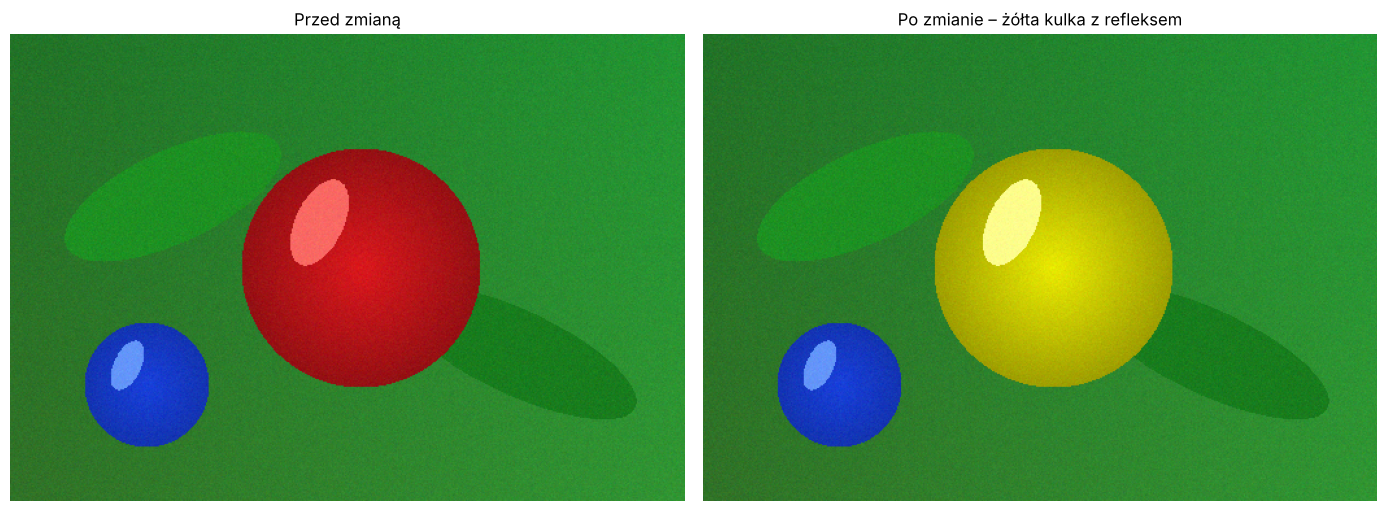

In [7]:
# Zadanie 2 – rozwiązanie
# Żółty w Color Pickerze: H = 60°, S = 100 %, V = 100 %  ->  RGB (255, 255, 0)
#
# Kolor podstawowy (intensywny żółty):  H = 60°, S = 100 %, V ≈ 92 %  ->  RGB (235, 235, 0)
# Kolor jaśniejszy (refleks):           H = 60°, S ≈ 45 %,  V = 100 % ->  RGB (255, 255, 140)

zolty_podstawowy = (235, 235, 0)
zolty_refleks    = (255, 255, 140)

# Kontrola w OpenCV (H w zakresie 0–179, więc 60° -> 30)
for nazwa, rgb in [("podstawowy", zolty_podstawowy), ("refleks", zolty_refleks)]:
    h, s, v = cv2.cvtColor(np.uint8([[rgb]]), cv2.COLOR_RGB2HSV)[0, 0]
    print(f"{nazwa:10s} RGB={rgb}  ->  OpenCV HSV = ({h}, {s}, {v})"
          f"  ->  H={2*h}°, S={s/255*100:.0f}%, V={v/255*100:.0f}%")

kolory_zolte = dict(kolory)
kolory_zolte["obiekt1"]  = zolty_podstawowy   # duża kulka zmienia kolor na żółty
kolory_zolte["refleks1"] = zolty_refleks      # jaśniejsza plamka na kulce

obraz_zolty = generuj_scene(kolory_zolte)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(obraz); ax[0].set_title("Przed zmianą")
ax[1].imshow(obraz_zolty); ax[1].set_title("Po zmianie – żółta kulka z refleksem")
for a_ in ax: a_.axis("off")
plt.tight_layout()
plt.show()

**Odpowiedź do Zadania 2**

| Kolor | H | S | V | RGB |
|---|---|---|---|---|
| żółty z Color Pickera | 60° | 100 % | 100 % | (255, 255, 0) |
| kolor podstawowy kulki | 60° | 100 % | 92 % | (235, 235, 0) |
| kolor refleksu | 60° | 45 % | 100 % | (255, 255, 140) |

Po wygenerowaniu obrazu duża kulka jest żółta, a jaśniejsza plamka (refleks) jest wyraźnie widoczna.

*Dlaczego pomimo różnych wartości RGB oba kolory są postrzegane jako odcienie żółtego?*
Oba kolory mają tę samą wartość **H = 60°**, czyli ten sam odcień. W RGB żółty powstaje, gdy R i G są równe i większe od B. W obu kolorach R = G, a zmienia się tylko ilość „bieli” (B = 0 lub 140) i ogólna jasność. To zmienia nasycenie i jasność, ale nie rodzaj barwy.

*Które składowe HSV zmieniły się podczas rozjaśniania koloru?*
H się nie zmieniło. **S** zmalało (100 % → 45 %), bo kolor zbliżył się do bieli. **V** wzrosło (92 % → 100 %), bo kolor stał się jaśniejszy.

## 5. Przestrzeń YCrCb – jasność i chrominancja

W przestrzeni YCrCb:
- **Y** – składowa związana z jasnością (luminancją);
- **Cr** – składowa różnicowa związana z kolorem czerwonym;
- **Cb** – składowa różnicowa związana z kolorem niebieskim.

Rozdzielenie jasności i chrominancji jest wykorzystywane m.in. w przetwarzaniu i kompresji obrazów.

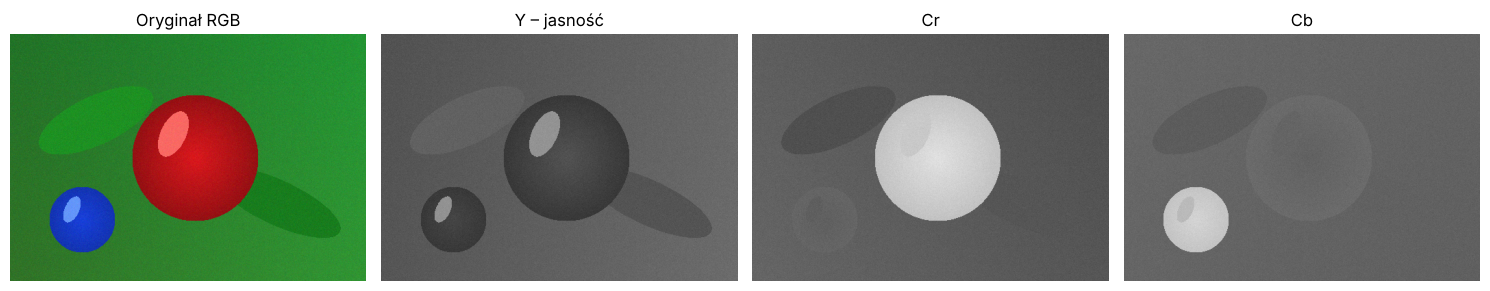

In [8]:
ycrcb = cv2.cvtColor(obraz, cv2.COLOR_RGB2YCrCb)
Y, Cr, Cb = ycrcb[:, :, 0], ycrcb[:, :, 1], ycrcb[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(obraz); ax[0].set_title("Oryginał RGB")
ax[1].imshow(Y, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Y – jasność")
ax[2].imshow(Cr, cmap="gray", vmin=0, vmax=255); ax[2].set_title("Cr")
ax[3].imshow(Cb, cmap="gray", vmin=0, vmax=255); ax[3].set_title("Cb")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

## 6. Przestrzeń CIELAB – opis barw z uwzględnieniem percepcji

CIELAB opisuje kolor za pomocą:
- **L\*** – jasność;
- **a\*** – oś od zieleni (wartości ujemne) do czerwieni (wartości dodatnie);
- **b\*** – oś od niebieskiego (wartości ujemne) do żółtego (wartości dodatnie).

Przestrzeń zaprojektowano tak, aby odległości między kolorami lepiej odpowiadały różnicom postrzeganym przez człowieka niż odległości w RGB.

OpenCV zapisuje kanały w reprezentacji 8-bitowej. Kanały a i b są przesunięte i przeskalowane, dlatego poniżej oglądamy ich obrazy w surowej reprezentacji, a nie bezpośrednie wartości fizyczne L*, a* i b*.

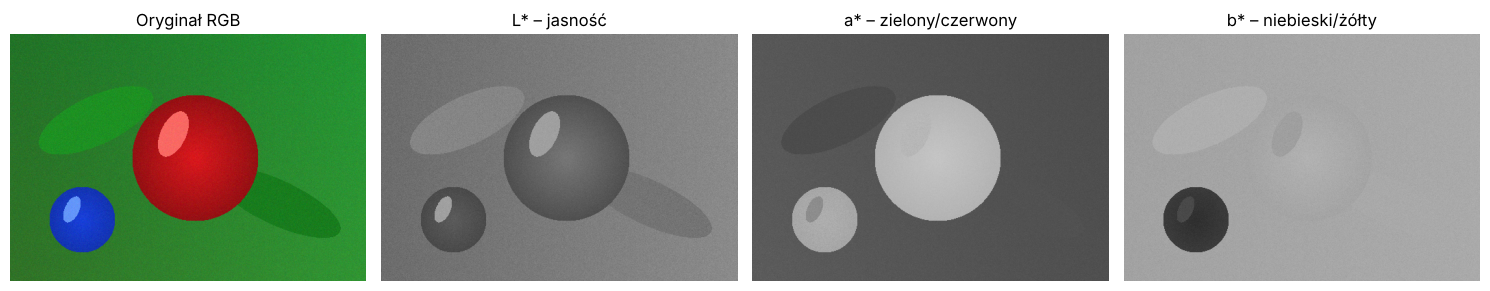

In [9]:
lab = cv2.cvtColor(obraz, cv2.COLOR_RGB2LAB)
L, a, b = lab[:, :, 0], lab[:, :, 1], lab[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(obraz); ax[0].set_title("Oryginał RGB")
ax[1].imshow(L, cmap="gray", vmin=0, vmax=255); ax[1].set_title("L* – jasność")
ax[2].imshow(a, cmap="gray", vmin=0, vmax=255); ax[2].set_title("a* – zielony/czerwony")
ax[3].imshow(b, cmap="gray", vmin=0, vmax=255); ax[3].set_title("b* – niebieski/żółty")
for a_ in ax: a_.axis("off")
plt.tight_layout()
plt.show()